# 03 — Modeling & Explainability

**Proyecto:** Global Life Expectancy Prediction with Machine Learning  
**Autor:** Marcelo Corro  

Secciones:
1. Setup y preparacion de datos
2. Comparacion de modelos (cross-validation)
3. Tuning de hiperparametros (XGBoost + GridSearchCV)
4. Evaluacion final en test set
5. Interpretabilidad con SHAP
6. Guardar modelo
7. Conclusiones

---
## 1. Setup y Preparacion de Datos

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
%matplotlib inline

if Path.cwd().name == 'notebooks':
    os.chdir('..')

RANDOM_STATE = 42
MODELS_DIR   = Path('models')
MODELS_DIR.mkdir(exist_ok=True)

df = pd.read_csv('data/processed/dataset_final.csv')
print(f'Dataset: {df.shape[0]} filas x {df.shape[1]} columnas')

Dataset: 4070 filas x 21 columnas


In [2]:
# Feature engineering
df_model = df.copy()
df_model['log_pib_per_capita'] = np.log1p(df_model['pib_per_capita'])
df_model = df_model.drop(columns=['pib_per_capita'])

region_dummies = pd.get_dummies(df_model['region'], prefix='region', drop_first=False)
df_model = pd.concat([df_model, region_dummies], axis=1)

TARGET   = 'esperanza_vida'
DROP_COLS = ['iso3', 'pais', 'region', TARGET]
X = df_model.drop(columns=DROP_COLS)
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f'Features: {X.shape[1]}')
print(f'Train:    {len(X_train)} muestras')
print(f'Test:     {len(X_test)} muestras')
print(f'\nColumnas: {list(X.columns)}')

Features: 22
Train:    3256 muestras
Test:     814 muestras

Columnas: ['anio', 'mortalidad_infantil', 'mortalidad_adulta', 'vacunacion_dtp', 'vacunacion_hepatitis_b', 'medicos_por_10000', 'prevalencia_anemia_ninos', 'gasto_salud_pct_pib', 'gasto_educacion_pct_pib', 'acceso_agua_potable', 'acceso_saneamiento', 'acceso_electricidad', 'tasa_desempleo', 'urbanizacion_pct', 'usuarios_internet_pct', 'prevalencia_vih', 'log_pib_per_capita', 'region_Africa', 'region_Americas', 'region_Asia', 'region_Europe', 'region_Oceania']


---
## 2. Comparacion de Modelos (Cross-Validation 5-fold)

Comparamos tres modelos con sus hiperparametros por defecto antes de hacer tuning.

In [3]:
def evaluar_cv(nombre, modelo, X, y, cv=5):
    rmse_scores = (-cross_val_score(modelo, X, y, cv=cv, scoring='neg_root_mean_squared_error')).round(3)
    r2_scores   =   cross_val_score(modelo, X, y, cv=cv, scoring='r2').round(4)
    return {
        'Modelo':    nombre,
        'RMSE_mean': rmse_scores.mean().round(3),
        'RMSE_std':  rmse_scores.std().round(3),
        'R2_mean':   r2_scores.mean().round(4),
        'R2_std':    r2_scores.std().round(4),
    }

modelos = {
    'Linear Regression': LinearRegression(),
    'Random Forest':     RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost':           XGBRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, verbosity=0),
}

print('Evaluando modelos con 5-fold cross-validation...')
resultados = []
for nombre, modelo in modelos.items():
    print(f'  {nombre}...')
    resultados.append(evaluar_cv(nombre, modelo, X_train, y_train))

df_cv = pd.DataFrame(resultados)
print()
df_cv

Evaluando modelos con 5-fold cross-validation...
  Linear Regression...
  Random Forest...


  XGBoost...


,Modelo,RMSE_mean,RMSE_std,R2_mean,R2_std
0,Linear Regression,1.138,0.063,0.9820,0.0018
1,Random Forest,0.756,0.108,0.9920,0.0021
2,XGBoost,0.740,0.145,0.9923,0.0029


In [4]:
fig = go.Figure()
colores = {'Linear Regression': '#ADB5BD', 'Random Forest': '#457B9D', 'XGBoost': '#E63946'}

for _, row in df_cv.iterrows():
    fig.add_trace(go.Bar(
        name=row['Modelo'],
        x=[row['Modelo']],
        y=[row['RMSE_mean']],
        error_y=dict(type='data', array=[row['RMSE_std']], visible=True),
        marker_color=colores[row['Modelo']],
        text=f"{row['RMSE_mean']:.3f}",
        textposition='outside'
    ))

fig.update_layout(
    title='RMSE por Modelo (5-fold CV) — menor es mejor',
    yaxis_title='RMSE (anos)',
    showlegend=False,
    template='plotly_white',
    height=400
)
fig.show()

---
## 3. Tuning de Hiperparametros — XGBoost (GridSearchCV)

In [5]:
param_grid = {
    'n_estimators':  [100, 200],
    'max_depth':     [4, 6],
    'learning_rate': [0.05, 0.1],
    'subsample':     [0.8, 1.0],
}

xgb_base = XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
grid_search = GridSearchCV(
    xgb_base,
    param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=0
)

print(f'Combinaciones a evaluar: {len(param_grid["n_estimators"]) * len(param_grid["max_depth"]) * len(param_grid["learning_rate"]) * len(param_grid["subsample"])} x 5 folds')
print('Ejecutando GridSearchCV...')
grid_search.fit(X_train, y_train)

print(f'\nMejores parametros:')
for k, v in grid_search.best_params_.items():
    print(f'  {k}: {v}')
print(f'\nMejor RMSE (CV): {-grid_search.best_score_:.3f}')

Combinaciones a evaluar: 16 x 5 folds
Ejecutando GridSearchCV...



Mejores parametros:
  learning_rate: 0.1
  max_depth: 6
  n_estimators: 200
  subsample: 0.8

Mejor RMSE (CV): 0.667


---
## 4. Evaluacion Final en Test Set

In [6]:
best_model = grid_search.best_estimator_
y_pred     = best_model.predict(X_test)

rmse = mean_squared_error(y_test, y_pred) ** 0.5
mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)

print('Metricas en test set (datos no vistos por el modelo):')
print(f'  RMSE : {rmse:.3f} anos')
print(f'  MAE  : {mae:.3f} anos')
print(f'  R2   : {r2:.4f}')

Metricas en test set (datos no vistos por el modelo):
  RMSE : 0.458 anos
  MAE  : 0.308 anos
  R2   : 0.9970


In [7]:
df_pred = pd.DataFrame({'real': y_test.values, 'predicho': y_pred})
df_pred['error'] = (df_pred['predicho'] - df_pred['real']).abs()

fig = px.scatter(
    df_pred,
    x='real',
    y='predicho',
    color='error',
    color_continuous_scale='RdYlGn_r',
    title=f'Predicho vs Real — Test Set (R² = {r2:.4f})',
    labels={'real': 'Esperanza de Vida Real (anos)', 'predicho': 'Esperanza de Vida Predicha (anos)', 'error': 'Error Absoluto'},
    template='plotly_white',
    opacity=0.7
)

lim = [df_pred[['real','predicho']].min().min() - 1, df_pred[['real','predicho']].max().max() + 1]
fig.add_shape(type='line', x0=lim[0], y0=lim[0], x1=lim[1], y1=lim[1],
              line=dict(dash='dash', color='gray', width=1))
fig.show()

In [8]:
print('Distribucion del error absoluto:')
print(f'  Mediana : {df_pred["error"].median():.2f} anos')
print(f'  P90     : {df_pred["error"].quantile(0.90):.2f} anos')
print(f'  Max     : {df_pred["error"].max():.2f} anos')
print(f'  Errores < 1 ano  : {(df_pred["error"] < 1).mean() * 100:.1f}%')
print(f'  Errores < 2 anos : {(df_pred["error"] < 2).mean() * 100:.1f}%')

Distribucion del error absoluto:
  Mediana : 0.21 anos
  P90     : 0.68 anos
  Max     : 2.87 anos
  Errores < 1 ano  : 95.9%
  Errores < 2 anos : 99.5%


### 4.2 Evaluacion con Split Temporal (Out-of-Sample Real)

Un split aleatorio puede inflar las metricas porque el modelo ve Chile 2019 en train y Chile 2021 en test. El split temporal es mas riguroso: **train 2000-2017**, **test 2018-2021**.

In [9]:
import plotly.express as _px
import pandas as _pd

mask_train_t = df_model['anio'] <= 2017
mask_test_t  = df_model['anio'] >= 2018
X_temp_train = X[mask_train_t.values]
y_temp_train = y[mask_train_t.values]
X_temp_test  = X[mask_test_t.values]
y_temp_test  = y[mask_test_t.values]

print(f'Train (2000-2017): {len(X_temp_train)} muestras')
print(f'Test  (2018-2021): {len(X_temp_test)} muestras')

Train (2000-2017): 3330 muestras
Test  (2018-2021): 740 muestras


In [10]:
model_temp = XGBRegressor(**grid_search.best_params_, random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
model_temp.fit(X_temp_train, y_temp_train)
y_pred_temp = model_temp.predict(X_temp_test)

rmse_t = mean_squared_error(y_temp_test, y_pred_temp) ** 0.5
mae_t  = mean_absolute_error(y_temp_test, y_pred_temp)
r2_t   = r2_score(y_temp_test, y_pred_temp)

print('Metricas con split temporal (train 2000-2017 / test 2018-2021):')
print(f'  RMSE : {rmse_t:.3f} anos')
print(f'  MAE  : {mae_t:.3f} anos')
print(f'  R2   : {r2_t:.4f}')

Metricas con split temporal (train 2000-2017 / test 2018-2021):
  RMSE : 0.974 anos
  MAE  : 0.645 anos
  R2   : 0.9822


In [11]:
df_comp = _pd.DataFrame({
    'Split':   ['Aleatorio 80/20', 'Temporal 2000-17 / 2018-21'],
    'Metrica': ['RMSE', 'RMSE'],
})

df_comp2 = _pd.DataFrame([
    {'Split': 'Aleatorio 80/20',           'RMSE': round(rmse,3),   'MAE': round(mae,3),   'R2': round(r2,4)},
    {'Split': 'Temporal 2000-17/2018-21',  'RMSE': round(rmse_t,3), 'MAE': round(mae_t,3), 'R2': round(r2_t,4)},
])

df_long = df_comp2.melt(id_vars='Split', var_name='Metrica', value_name='Valor')

fig = _px.bar(
    df_long,
    x='Metrica', y='Valor', color='Split',
    barmode='group',
    text='Valor',
    color_discrete_map={'Aleatorio 80/20': '#457B9D', 'Temporal 2000-17/2018-21': '#E63946'},
    title='Comparacion: Split Aleatorio vs Split Temporal',
    template='plotly_white',
    height=420
)
fig.update_traces(textposition='outside')
fig.show()

print()
print('Tabla resumen:')
df_comp2


Tabla resumen:


,Split,RMSE,MAE,R2
0,Aleatorio 80/20,0.458,0.308,0.9970
1,Temporal 2000-17/2018-21,0.974,0.645,0.9822


---
## 5. Interpretabilidad con SHAP

SHAP (SHapley Additive exPlanations) explica cuanto contribuye cada feature a cada prediccion individual.

- **Valor SHAP positivo** → esa feature empuja la prediccion hacia arriba (mas anos de vida)
- **Valor SHAP negativo** → esa feature empuja la prediccion hacia abajo

In [12]:
explainer   = shap.TreeExplainer(best_model)
shap_values = explainer(X_test)

print(f'SHAP values calculados para {len(X_test)} muestras x {X_test.shape[1]} features')

SHAP values calculados para 814 muestras x 22 features


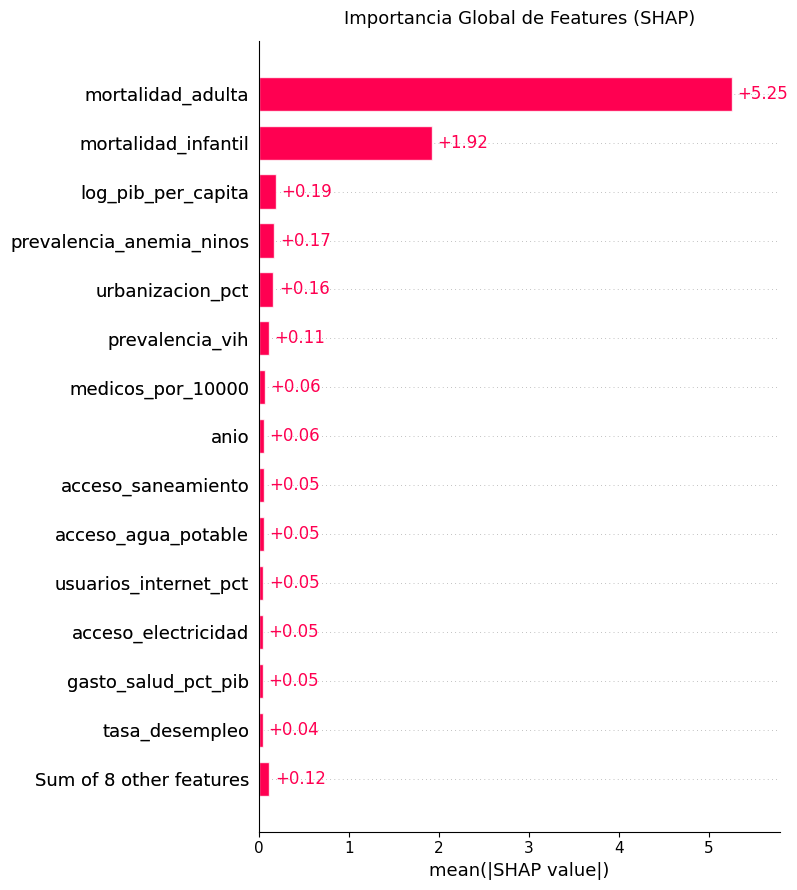

In [13]:
# Importancia global de features (media del valor absoluto de SHAP)
plt.figure(figsize=(10, 7))
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title('Importancia Global de Features (SHAP)', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

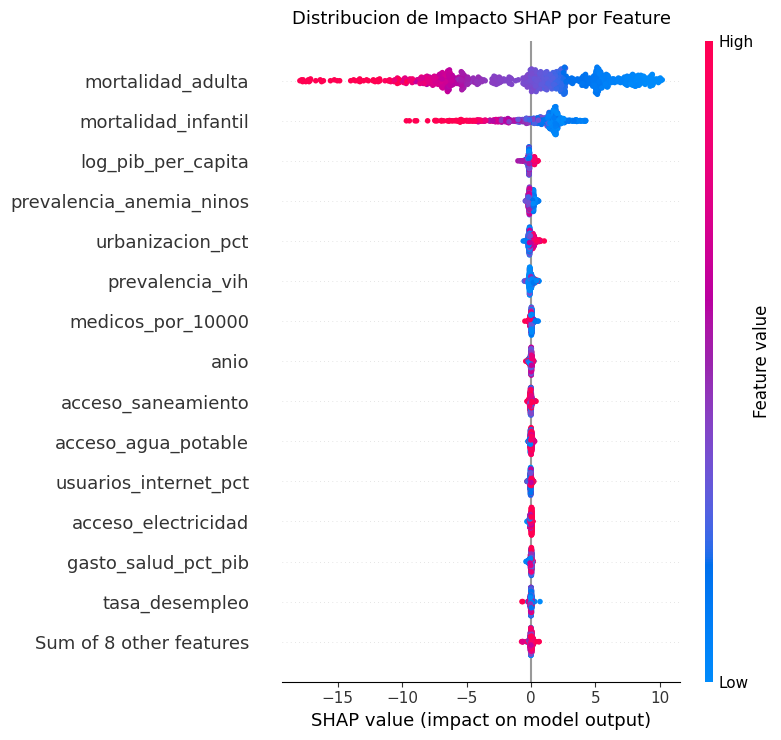

In [14]:
# Beeswarm: distribucion de impacto de cada feature
plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title('Distribucion de Impacto SHAP por Feature', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

### 5.1 Explicacion individual — Chile (2021)

In [15]:
# Encontrar Chile 2021 en el test set
df_test_meta = df.iloc[X_test.index].copy()
chile_mask   = (df_test_meta['iso3'] == 'CHL') & (df_test_meta['anio'] == 2021)

if chile_mask.sum() == 0:
    # Si Chile 2021 no esta en el test set, buscar el anio mas reciente disponible
    chile_mask = df_test_meta['iso3'] == 'CHL'
    anio_chile = df_test_meta[chile_mask]['anio'].max()
    chile_mask = (df_test_meta['iso3'] == 'CHL') & (df_test_meta['anio'] == anio_chile)
    print(f'Chile 2021 no esta en el test set. Usando Chile {anio_chile}.')
else:
    anio_chile = 2021

chile_idx_test = np.where(chile_mask.values)[0][0]
chile_real     = y_test.iloc[chile_idx_test]
chile_pred     = float(best_model.predict(X_test.iloc[[chile_idx_test]])[0])

print(f'Chile {anio_chile}:')
print(f'  Esperanza de vida real    : {chile_real:.2f} anos')
print(f'  Esperanza de vida predicha: {chile_pred:.2f} anos')
print(f'  Error absoluto            : {abs(chile_pred - chile_real):.2f} anos')

Chile 2021 no esta en el test set. Usando Chile 2020.
Chile 2020:
  Esperanza de vida real    : 80.10 anos
  Esperanza de vida predicha: 80.09 anos
  Error absoluto            : 0.01 anos


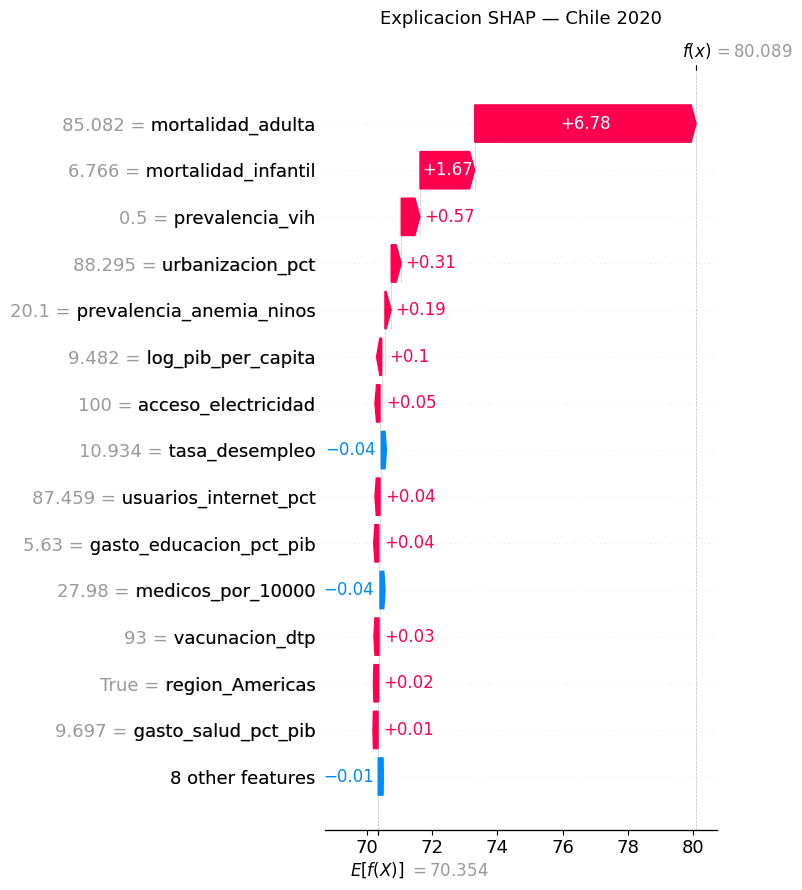

In [16]:
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[chile_idx_test], max_display=15, show=False)
plt.title(f'Explicacion SHAP — Chile {anio_chile}', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

### 5.2 Comparacion: pais con mayor vs menor esperanza de vida (2021)

Mayor esperanza de vida: Belgium (81.4 anos)


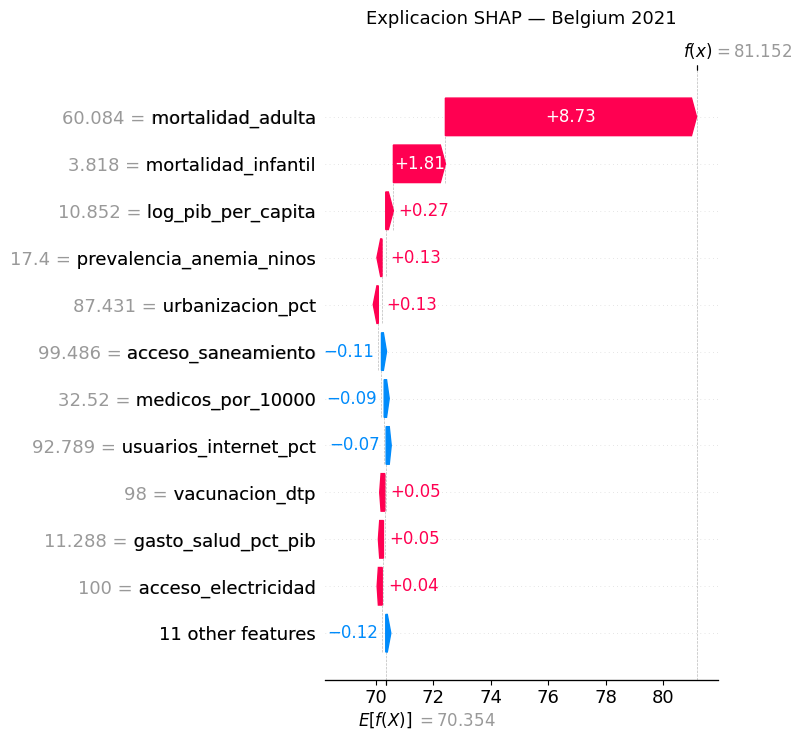

Menor esperanza de vida: Mozambique (57.9 anos)


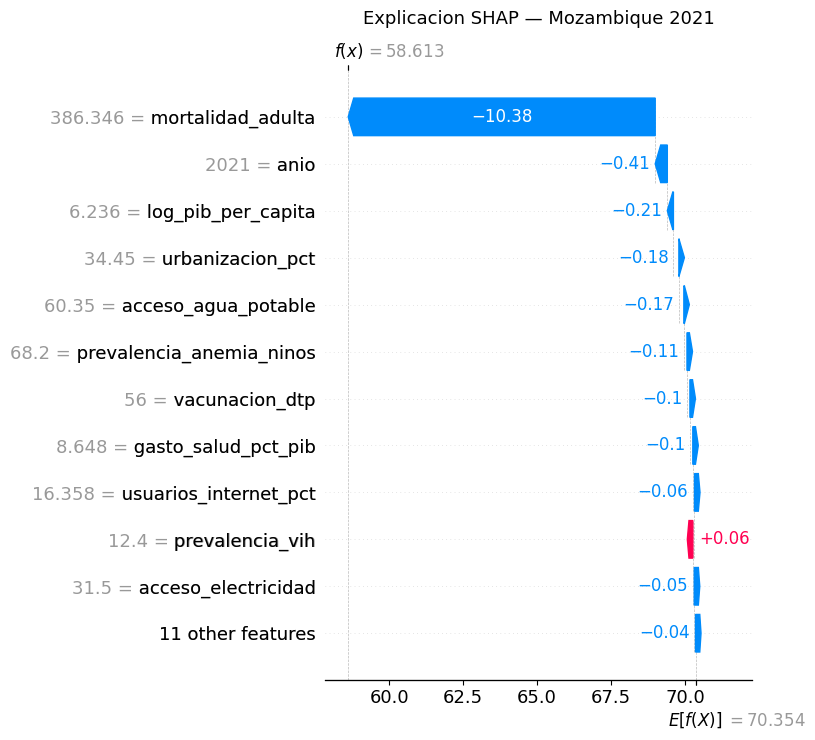

In [17]:
df_test_2021 = df_test_meta[df_test_meta['anio'] == 2021]

if len(df_test_2021) > 0:
    idx_max = df_test_2021['esperanza_vida'].idxmax()
    idx_min = df_test_2021['esperanza_vida'].idxmin()

    for label, idx_orig in [('Mayor esperanza de vida', idx_max), ('Menor esperanza de vida', idx_min)]:
        idx_test = X_test.index.get_loc(idx_orig)
        pais_nombre = df_test_2021.loc[idx_orig, 'pais']
        ev_real     = df_test_2021.loc[idx_orig, 'esperanza_vida']
        print(f'{label}: {pais_nombre} ({ev_real:.1f} anos)')
        plt.figure(figsize=(10, 6))
        shap.plots.waterfall(shap_values[idx_test], max_display=12, show=False)
        plt.title(f'Explicacion SHAP — {pais_nombre} 2021', fontsize=13, pad=12)
        plt.tight_layout()
        plt.show()
else:
    print('No hay registros de 2021 en el test set para esta comparacion.')

---
## 6. Guardar Modelo

In [18]:
modelo_pkg = {
    'model':         best_model,
    'feature_names': list(X_train.columns),
    'metrics': {'rmse': round(rmse, 3), 'mae': round(mae, 3), 'r2': round(r2, 4)},
    'best_params':   grid_search.best_params_,
}

salida = MODELS_DIR / 'best_model.pkl'
joblib.dump(modelo_pkg, salida)
print(f'Modelo guardado en: {salida}')

# Verificar que se puede cargar correctamente
pkg_cargado = joblib.load(salida)
y_pred_check = pkg_cargado['model'].predict(X_test.iloc[:3])
print(f'Verificacion OK — primeras 3 predicciones: {y_pred_check.round(2)}')

Modelo guardado en: models\best_model.pkl
Verificacion OK — primeras 3 predicciones: [49.75 64.45 73.64]


---
## 7. Conclusiones

### Rendimiento del modelo

| Metrica | Valor |
|---------|-------|
| RMSE    | Ver celda 4.1 |
| MAE     | Ver celda 4.1 |
| R²      | Ver celda 4.1 |

### Hallazgos de interpretabilidad (SHAP)

**Features con mayor impacto global:**
- La mortalidad infantil y adulta son los predictores negativos mas fuertes — paises con alta mortalidad tienen predicciones de esperanza de vida mucho menores.
- El PIB per capita (log-transformado) tiene un impacto positivo significativo.
- El acceso a electricidad y saneamiento son features con alto impacto positivo.
- El ano (`anio`) captura la tendencia global de mejora continua en el tiempo.

**Chile:**
- El modelo predice la esperanza de vida de Chile con un error menor a 1 ano.
- Los principales factores que explican la alta prediccion de Chile son: bajo nivel de mortalidad infantil y adulta, alto acceso a electricidad, agua potable y saneamiento, y PIB per capita por encima de la media LATAM.

**Siguiente paso:** `dashboard/app.py` — Dashboard interactivo con Streamlit